##### Copyright 2023 The MediaPipe Authors. All Rights Reserved.

In [ ]:
#@title Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
# https://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

In [10]:
!ffmpeg -i "Data/Raw/2_21_10.MOV" -r 30 "Data/Raw_30fps/2_21_10_30fps.MOV"

ffmpeg version 4.2.4-1ubuntu0.1 Copyright (c) 2000-2020 the FFmpeg developers
  built with gcc 9 (Ubuntu 9.3.0-10ubuntu2)
  configuration: --prefix=/usr --extra-version=1ubuntu0.1 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --enable-avresample --disable-filter=resample --enable-avisynth --enable-gnutls --enable-ladspa --enable-libaom --enable-libass --enable-libbluray --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libgme --enable-libgsm --enable-libjack --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-libpulse --enable-librsvg --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libssh --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-l

In [11]:
import cv2

def get_video_fps(video_path):
    # Open the video file
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print("Error: Could not open video.")
        return None

    # Get the FPS using the CAP_PROP_FPS property
    fps = cap.get(cv2.CAP_PROP_FPS)

    # Release the video file
    cap.release()

    return fps

In [14]:
# Example usage
video_path = "Data/Raw_30fps/2_21_10_30fps.MOV"
fps = get_video_fps(video_path)
if fps:
    print(f"The video's FPS is: {fps}")

The video's FPS is: 30.0


# Face Landmarks Detection with MediaPipe Tasks

This notebook shows you how to use MediaPipe Tasks Python API to detect face landmarks from images.

## Preparation

Let's start with installing MediaPipe.

In [ ]:
!pip install -q mediapipe

Then download the off-the-shelf model bundle(s). Check out the [MediaPipe documentation](https://developers.google.com/mediapipe/solutions/vision/face_landmarker#models) for more information about these model bundles.

In [2]:
!wget -O face_landmarker_v2_with_blendshapes.task -q https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task

## Visualization utilities

In [1]:
#@markdown We implemented some functions to visualize the face landmark detection results. <br/> Run the following cell to activate the functions.

from mediapipe import solutions
from mediapipe.framework.formats import landmark_pb2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

    
def draw_landmarks_on_image(rgb_image, detection_result):
    face_landmarks_list = detection_result.face_landmarks
    annotated_image = np.copy(rgb_image)

    # Loop through the detected faces to visualize.
    for idx in range(len(face_landmarks_list)):
        face_landmarks = face_landmarks_list[idx]

        # Draw the face landmarks.
        face_landmarks_proto = landmark_pb2.NormalizedLandmarkList()
        face_landmarks_proto.landmark.extend([
          landmark_pb2.NormalizedLandmark(x=landmark.x, y=landmark.y, z=landmark.z) for landmark in face_landmarks
        ])

        solutions.drawing_utils.draw_landmarks(
            image=annotated_image,
            landmark_list=face_landmarks_proto,
            connections=mp.solutions.face_mesh.FACEMESH_TESSELATION,
            landmark_drawing_spec=None,
            connection_drawing_spec=mp.solutions.drawing_styles
            .get_default_face_mesh_tesselation_style())
        solutions.drawing_utils.draw_landmarks(
            image=annotated_image,
            landmark_list=face_landmarks_proto,
            connections=mp.solutions.face_mesh.FACEMESH_CONTOURS,
            landmark_drawing_spec=None,
            connection_drawing_spec=mp.solutions.drawing_styles
            .get_default_face_mesh_contours_style())
        solutions.drawing_utils.draw_landmarks(
            image=annotated_image,
            landmark_list=face_landmarks_proto,
            connections=mp.solutions.face_mesh.FACEMESH_IRISES,
              landmark_drawing_spec=None,
              connection_drawing_spec=mp.solutions.drawing_styles
              .get_default_face_mesh_iris_connections_style())

    return annotated_image

def plot_face_blendshapes_bar_graph(face_blendshapes):
    # Extract the face blendshapes category names and scores.
    face_blendshapes_names = [face_blendshapes_category.category_name for face_blendshapes_category in face_blendshapes]
    face_blendshapes_scores = [face_blendshapes_category.score for face_blendshapes_category in face_blendshapes]
    # The blendshapes are ordered in decreasing score value.
    face_blendshapes_ranks = range(len(face_blendshapes_names))

    fig, ax = plt.subplots(figsize=(12, 12))
    bar = ax.barh(face_blendshapes_ranks, face_blendshapes_scores, label=[str(x) for x in face_blendshapes_ranks])
    ax.set_yticks(face_blendshapes_ranks)  # Set ticks for y-axis
    ax.set_yticklabels(face_blendshapes_names)  # Set tick labels separately
    ax.invert_yaxis()

    # Label each bar with values
    for score, patch in zip(face_blendshapes_scores, bar.patches):
        plt.text(patch.get_x() + patch.get_width(), patch.get_y() + patch.get_height() / 2,
                 f"{score:.4f}", va="center", ha="left")

    ax.set_xlabel('Score')
    ax.set_title("Face Blendshapes")
    plt.tight_layout()
    plt.show()


## Download test image

Let's grab a test image that we'll use later. The image is from [Unsplash](https://unsplash.com/photos/mt2fyrdXxzk).

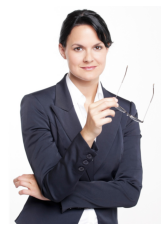

In [2]:
# Download the image
import requests

url = "https://storage.googleapis.com/mediapipe-assets/business-person.png"
response = requests.get(url)
with open("image.png", "wb") as file:
    file.write(response.content)

# Display the image
import cv2
from matplotlib import pyplot as plt

# Read the image using OpenCV
img = cv2.imread("image.png")

# Convert BGR to RGB for correct color rendering
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Display using matplotlib
plt.imshow(img_rgb)
plt.axis('off')  # Hide axes for better visualization
plt.show()


Optionally, you can upload your own image. If you want to do so, uncomment and run the cell below.

In [3]:
# from google.colab import files
# uploaded = files.upload()

# for filename in uploaded:
#   content = uploaded[filename]
#   with open(filename, 'wb') as f:
#     f.write(content)

# if len(uploaded.keys()):
#   IMAGE_FILE = next(iter(uploaded))
#   print('Uploaded file:', IMAGE_FILE)

## Running inference and visualizing the results

Here are the steps to run face landmark detection using MediaPipe.

Check out the [MediaPipe documentation](https://developers.google.com/mediapipe/solutions/vision/face_landmarker/python) to learn more about configuration options that this task supports.


In [4]:
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
import cv2
import numpy as np
from tqdm import tqdm

# STEP 1: Create a FaceLandmarker object.
base_options = python.BaseOptions(model_asset_path='face_landmarker_v2_with_blendshapes.task')
options = vision.FaceLandmarkerOptions(
    base_options=base_options,
    output_face_blendshapes=True,
    output_facial_transformation_matrixes=True,
    num_faces=1
)
detector = vision.FaceLandmarker.create_from_options(options)

def draw_landmarks_on_frame(frame, detection_result):
    """
    Draws face landmarks on a single video frame.

    Parameters:
    - frame: numpy.ndarray
        The video frame as a NumPy array.
    - detection_result: FaceLandmarkerResult
        The detection result containing face landmarks.

    Returns:
    - annotated_frame: numpy.ndarray
        The frame with face landmarks drawn.
    """
    annotated_frame = frame.copy()
    for face_landmarks in detection_result.face_landmarks:
        for landmark in face_landmarks:
            # Extract normalized coordinates
            x = int(landmark.x * annotated_frame.shape[1])  # Scale to frame width
            y = int(landmark.y * annotated_frame.shape[0])  # Scale to frame height
            # Draw a small circle at the landmark position
            cv2.circle(annotated_frame, (x, y), radius=2, color=(0, 255, 0), thickness=-1)
    return annotated_frame

def process_image(image_path, output_path):
    """
    Processes an image, detects landmarks, and saves the annotated image.

    Parameters:
    - image_path: str
        Path to the input image.
    - output_path: str
        Path to save the annotated image.

    Returns:
    - blendshape_results: list
        A list of detected blendshape scores.
    """
    # Load and process the image
    image = mp.Image.create_from_file(image_path)
    detection_result = detector.detect(image)

    # Convert image to OpenCV format and draw landmarks
    image_array = cv2.cvtColor(image.numpy_view(), cv2.COLOR_RGB2BGR)
    annotated_image = draw_landmarks_on_frame(image_array, detection_result)
    cv2.imwrite(output_path, annotated_image)

    # Collect blendshape results
    blendshape_results = [
        {blendshape.category_name: blendshape.score for blendshape in face_blendshapes}
        for face_blendshapes in detection_result.face_blendshapes
    ]

    print(f"Annotated image saved at: {output_path}")
    return blendshape_results

import cv2
import mediapipe as mp
from tqdm import tqdm

def process_video(video_path, save=False, start_second=0, end_second=None):
    """
    Processes a video, detects landmarks in each frame within the specified range, 
    and saves the annotated video with frame numbers written on each frame.

    Parameters:
    - video_path: str
        Path to the input video.
    - output_path: str
        Path to save the annotated video.
    - start_second: int
        Start time in seconds for processing the video.
    - end_second: int or None
        End time in seconds for processing the video. If None, processes until the end of the video.

    Returns:
    - blendshape_results: list
        A list of detected blendshape scores for each frame.
    """
    cap = cv2.VideoCapture(video_path)
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    fps = int(cap.get(cv2.CAP_PROP_FPS))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    # Convert time to frame numbers
    start_frame = int(start_second * fps)
    end_frame = int(end_second * fps) if end_second is not None else total_frames

    # Ensure valid frame ranges
    start_frame = max(0, start_frame)
    end_frame = min(total_frames, end_frame)

    # Set the video capture to the start frame
    cap.set(cv2.CAP_PROP_POS_FRAMES, start_frame)

    # Create the video writer
    blendshape_results = []    
    frames = []
    detection_results = []
    
    # Create a progress bar
    total_process_frames = end_frame - start_frame
    with tqdm(total=total_process_frames, desc="Processing video", unit="frame") as pbar:
        current_frame = start_frame
        while cap.isOpened() and current_frame < end_frame:
            ret, frame = cap.read()
            frames.append(frame)
            if not ret:
                break

            # Convert the frame to an mp.Image object
            mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame)
            detection_result = detector.detect(mp_image)
            detection_results.append(detection_result)

            # Add the frame number as text on the frame
            frame_number_text = f"Frame: {current_frame + 1}"
            cv2.putText(annotated_frame, frame_number_text, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, 0), 2)

            annotated_frames.append(annotated_frame)

            frame_blendshapes = [
                {blendshape.category_name: blendshape.score for blendshape in face_blendshapes}
                for face_blendshapes in detection_result.face_blendshapes
            ]
            blendshape_results.append(frame_blendshapes)

            current_frame += 1
            pbar.update(1)

    cap.release()
    

    if save != False:
        output_path = save
        if save == True:
            if start_second <= 0:
                start_second = 'start'
            if end_second == None:
                end_second = 'end'
            output_path = f"output/{video_path.split('/')[-1].split('.')[0]}_{start_second}_{end_second}_annotated.{video_path.split('/')[-1].split('.')[1]}"
            
        out = cv2.VideoWriter(output_path, fourcc, fps, (width, height))
        with tqdm(total=len(annotated_frames), desc="Writing video", unit="frame") as pbar:
            for frame, detection_result in frames, detection_results:
                out.write(draw_landmarks_on_frame(frame, detection_result))
                pbar.update(1)
            out.release()

    print(f"Annotated video saved at: {output_path}")
    return blendshape_results, start_frame

In [5]:
from plotly import graph_objects as go
import numpy as np

def plot_blendshape_predictions(blendshape_predictions, starting_frame=0, frame_numbers=None):
    """
    Creates an interactive plot showing blendshape predictions over multiple frames.

    Parameters:
    - blendshape_predictions: list of dicts
        List of blendshape predictions for each frame.
    - frame_numbers: list of ints, optional
        List of frame numbers corresponding to the predictions. If not provided, indices are used.

    Returns:
    - fig: plotly.graph_objects.Figure
        The interactive figure.
    - missing_frames: list of ints
        List of frame indices where data is missing.
    """
    if frame_numbers is None:
        frame_numbers = list(range(len(blendshape_predictions)))

    # Collect unique blendshape names
    blendshape_names = list(blendshape_predictions[0][0].keys())

    # Initialize the figure
    fig = go.Figure()

    missing_frames = []

    # Function to compute moving average
    def moving_average(data, window_size):
        return np.convolve(data, np.ones(window_size)/window_size, mode='same')

    # Add a trace for each blendshape
    for blendshape in blendshape_names:
        y_values = []
        for i in range(len(blendshape_predictions)):
            frame = blendshape_predictions[i]
            if len(frame) != 0:
                y_values.append(frame[0][blendshape])
            else:
                y_values.append(0)
                missing_frames.append(i)

        # Calculate moving average
        y_moving_avg = moving_average(y_values, window_size=10)

        # Calculate percentage change
        y_percentage_change = [
            0 if i == 0 else ((y_values[i] - y_values[i - 1]) / max(abs(y_values[i - 1]), 1e-6)) * 100
            for i in range(len(y_values))
        ]

        # Plot the original values
        fig.add_trace(go.Scatter(
            x=[frame_number + starting_frame for frame_number in frame_numbers],
            y=y_values,
            mode='lines',
            name=f"{blendshape} (Raw)"
        ))

        # Plot the moving average
        fig.add_trace(go.Scatter(
            x=[frame_number + starting_frame for frame_number in frame_numbers],
            y=y_moving_avg,
            mode='lines',
            name=f"{blendshape} (Moving Avg)",
            line=dict(dash='dash')  # Dashed line for moving average
        ))

        # Plot percentage change
        fig.add_trace(go.Scatter(
            x=[frame_number + starting_frame for frame_number in frame_numbers],
            y=y_percentage_change,
            mode='lines',
            name=f"{blendshape} (Percentage Change)",
            line=dict(dash='dot')  # Dotted line for percentage change
        ))

    missing_frames = list(set(missing_frames))

    # Update layout
    fig.update_layout(
        title="Blendshape Predictions Over Frames",
        xaxis=dict(title="Frame Number"),
        yaxis=dict(title="Blendshape Value"),
        legend=dict(title="Blendshapes"),
        hovermode="x unified",  # Ensures hover shows values for all blendshapes at the same frame
        height=800,
    )

    return fig, missing_frames


In [6]:
blendshape_results, start_frame = process_video("Data/Raw/2_21_10.MOV", True, start_second=0, end_second=None)

Writing video: 100%|██████████| 18055/18055 [02:25<00:00, 124.06frame/s]

Annotated video saved at: output/2_21_10_start_end_annotated.MOV


In [7]:
df = pd.DataFrame([frame[0] for frame in blendshape_results])

In [8]:
df

,_neutral,browDownLeft,browDownRight,browInnerUp,browOuterUpLeft,browOuterUpRight,cheekPuff,cheekSquintLeft,cheekSquintRight,eyeBlinkLeft,...,mouthShrugLower,mouthShrugUpper,mouthSmileLeft,mouthSmileRight,mouthStretchLeft,mouthStretchRight,mouthUpperUpLeft,mouthUpperUpRight,noseSneerLeft,noseSneerRight
0,7.695646e-07,0.001233,0.000607,0.393720,0.448134,0.335748,0.000005,2.902819e-07,1.662217e-07,0.250389,...,0.470823,0.160175,0.000221,0.000141,0.000907,0.001216,0.002530,0.003368,0.000006,3.673751e-07
1,9.722409e-07,0.001321,0.001037,0.391277,0.417739,0.282155,0.000005,3.054745e-07,1.909800e-07,0.266906,...,0.577281,0.203160,0.000175,0.000127,0.000706,0.001653,0.002439,0.004174,0.000004,4.453878e-07
2,1.362608e-06,0.000890,0.001040,0.438582,0.387888,0.237335,0.000008,5.252652e-07,2.900019e-07,0.598047,...,0.680736,0.278903,0.000269,0.000139,0.002104,0.003445,0.003231,0.005326,0.000006,5.617704e-07
3,1.255177e-06,0.001119,0.000872,0.356985,0.435820,0.335420,0.000009,5.301292e-07,2.563445e-07,0.672123,...,0.698634,0.321519,0.000282,0.000155,0.001905,0.002126,0.004070,0.006622,0.000008,5.900243e-07
4,1.295965e-06,0.001209,0.001064,0.346412,0.386519,0.306597,0.000009,4.773162e-07,2.182876e-07,0.650055,...,0.701710,0.337884,0.000559,0.000316,0.003062,0.002781,0.005972,0.009943,0.000008,5.709334e-07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18050,1.075327e-06,0.011921,0.012467,0.127271,0.110322,0.090487,0.000004,1.629722e-07,1.619141e-07,0.269354,...,0.650946,0.155380,0.000064,0.000030,0.000960,0.001037,0.001163,0.001519,0.000002,4.249364e-07
18051,1.173820e-06,0.018598,0.020728,0.092172,0.087478,0.068493,0.000004,1.584745e-07,1.870906e-07,0.286145,...,0.599519,0.137043,0.000091,0.000042,0.001028,0.001418,0.001450,0.001593,0.000002,5.130799e-07
18052,9.654397e-07,0.017561,0.022102,0.116063,0.086084,0.063736,0.000003,1.736952e-07,1.891579e-07,0.253671,...,0.541166,0.131688,0.000060,0.000025,0.000875,0.000957,0.001234,0.001263,0.000002,4.712679e-07
18053,1.124058e-06,0.018011,0.016830,0.117208,0.081336,0.077365,0.000004,1.495726e-07,1.774375e-07,0.246076,...,0.607463,0.129057,0.000058,0.000027,0.000627,0.001044,0.001014,0.001128,0.000002,4.403009e-07


In [9]:
df.to_csv("out.csv")

In [22]:
fig, missing_frames = plot_blendshape_predictions(blendshape_results, start_frame)

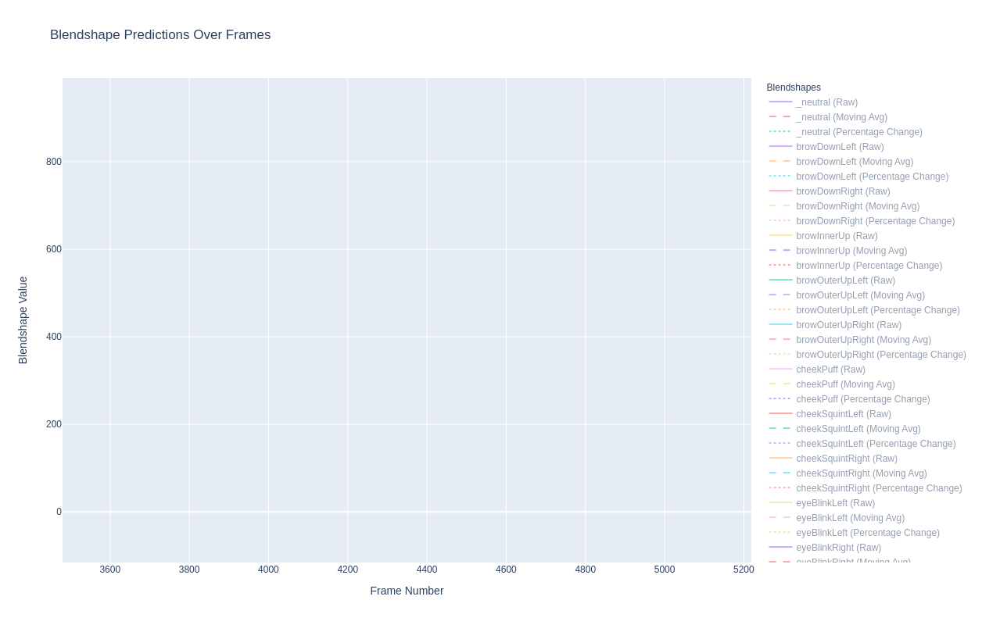

In [23]:
fig

In [10]:
import numpy as np
from collections import deque
from scipy.signal import savgol_filter
import numpy as np

class RealtimeBlinkDetector:
    def __init__(self, buffer_size=90, calibration_frames=300):
        """
        Initialize real-time blink detector
        
        Args:
            buffer_size: Number of frames to keep in rolling buffer (3 seconds at 30fps)
            calibration_frames: Number of frames for initial calibration
        """
        self.buffer_size = buffer_size
        self.calibration_frames = calibration_frames
        self.score_buffer = deque(maxlen=buffer_size)
        self.is_calibrated = False
        self.calibration_scores = []
        self.baseline_params = None
        
    def update(self, new_score):
        """
        Process new frame in real-time
        
        Args:
            new_score: New blink score from current frame
            
        Returns:
            is_blink: Boolean indicating if current frame is part of a blink
            confidence: Confidence score for the prediction
        """
        if not self.is_calibrated:
            return self._handle_calibration(new_score)
            
        # Add new score to rolling buffer
        self.score_buffer.append(new_score)
        
        # Get real-time prediction
        return self._detect_blink_realtime(new_score)
    
    def _handle_calibration(self, new_score):
        """Handle incoming frames during calibration period"""
        self.calibration_scores.append(new_score)
        
        if len(self.calibration_scores) >= self.calibration_frames:
            self._compute_baseline_params()
            self.is_calibrated = True
            return self._detect_blink_realtime(new_score)
            
        return False, 0.0
    
    def _compute_baseline_params(self):
        """Compute baseline parameters from calibration period"""
        scores = np.array(self.calibration_scores)
        
        # Calculate baseline statistics
        self.baseline_params = {
            'mean': np.mean(scores),
            'std': np.std(scores),
            'min': np.min(scores),
            'max': np.max(scores),
            'dynamic_range': np.max(scores) - np.min(scores)
        }
        
        # Calculate adaptive thresholds
        self._update_adaptive_thresholds()
    
    def _update_adaptive_thresholds(self):
        """Update adaptive thresholds based on recent signal history"""
        if len(self.score_buffer) < self.buffer_size // 2:
            return
            
        recent_scores = np.array(list(self.score_buffer))
        
        # Update dynamic threshold based on recent signal statistics
        self.current_threshold = (
            np.mean(recent_scores) -
            (np.std(recent_scores) * 
             (1 + np.abs(stats.skew(recent_scores))))
        )
    
    def _detect_blink_realtime(self, current_score):
        """
        Detect if current frame is part of a blink using real-time algorithm
        """
        # Update adaptive thresholds every N frames
        if len(self.score_buffer) % 30 == 0:  # Update every second at 30fps
            self._update_adaptive_thresholds()
        
        # Get recent scores for local context
        recent_scores = np.array(list(self.score_buffer))
        
        # Compute simple moving average for smoothing
        window_size = min(5, len(recent_scores))
        if window_size > 0:
            smooth_score = np.mean(recent_scores[-window_size:])
        else:
            smooth_score = current_score
        
        # Check for blink conditions
        is_blink = False
        confidence = 0.0
        
        if len(recent_scores) >= 3:
            # Condition 1: Significant drop from baseline
            score_diff = self.baseline_params['mean'] - smooth_score
            norm_diff = score_diff / self.baseline_params['dynamic_range']
            
            # Condition 2: Local minimum
            is_local_min = (
                len(recent_scores) >= 3 and
                recent_scores[-2] < recent_scores[-3] and
                recent_scores[-2] < recent_scores[-1]
            )
            
            # Condition 3: Rate of change
            if len(recent_scores) >= 3:
                derivative = recent_scores[-1] - recent_scores[-2]
                second_derivative = (recent_scores[-1] - 2*recent_scores[-2] + 
                                  recent_scores[-3])
            else:
                derivative = 0
                second_derivative = 0
            
            # Combined decision
            if smooth_score < self.current_threshold:
                confidence = norm_diff
                if confidence > 0.3:  # Minimum confidence threshold
                    is_blink = True
                    
                    # Increase confidence if other conditions are met
                    if is_local_min:
                        confidence += 0.2
                    if abs(derivative) > self.baseline_params['std']:
                        confidence += 0.1
                    if second_derivative > 0:  # Recovery phase
                        confidence += 0.1
                        
                    confidence = min(confidence, 1.0)  # Cap at 1.0
        
        return is_blink, confidence
    
    def get_current_stats(self):
        """Get current statistics about blink detection"""
        if not self.is_calibrated:
            return {
                'status': 'calibrating',
                'progress': len(self.calibration_scores) / self.calibration_frames
            }
        
        return {
            'status': 'running',
            'buffer_size': len(self.score_buffer),
            'current_threshold': self.current_threshold,
            'baseline_mean': self.baseline_params['mean'],
            'baseline_std': self.baseline_params['std']
        }

In [ ]:
# Example usage for image
image_blendshapes = process_image("image.png", "annotated_image.png")
print("Image Blendshapes:", image_blendshapes)

# Example usage for video
video_blendshapes = process_video("input_video.mp4", "annotated_video.mp4", start_second=10, end_second=30)
print("Video Blendshapes:", video_blendshapes)


In [74]:
video_blendshapes = process_video("Data/Raw/1_04_0.mp4", None, start_second=0, end_second=60)
print("Video Blendshapes:", video_blendshapes)

Processing video: 100%|██████████| 1500/1500 [00:46<00:00, 32.18frame/s]
IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



In [79]:
video_blendshapes = process_video("Data/Raw/1_04_0.mp4", "annotated_video_temp.mp4", start_second=0, end_second=60)
print("Video Blendshapes:", video_blendshapes)

Writing video: 100%|██████████| 1500/1500 [00:05<00:00, 281.87frame/s]IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)




In [7]:
process_video("Data/Raw/1_04_0.mp4", "annotated_video.mp4")

Annotated video saved at: annotated_video.mp4


We will also visualize the face blendshapes categories using a bar graph.

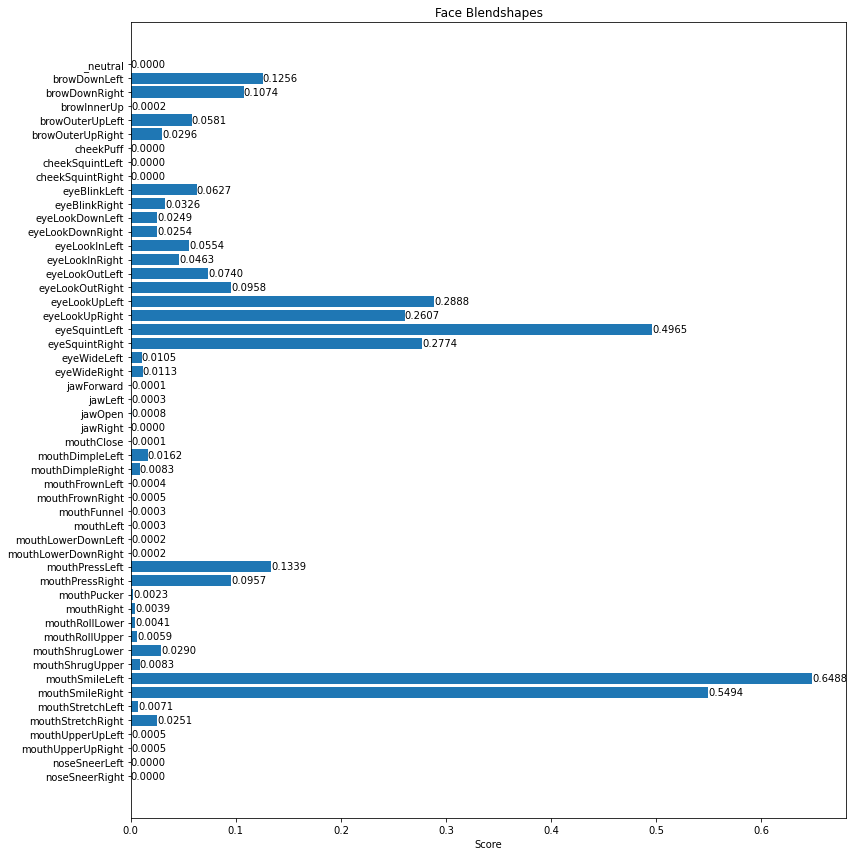

In [15]:
plot_face_blendshapes_bar_graph(detection_result.face_blendshapes[0])

And print the transformation matrix.

In [8]:
print(detection_result.facial_transformation_matrixes)

[array([[ 9.92207229e-01, -6.04891032e-02,  1.08933516e-01,
         1.18722856e+00],
       [ 9.10698548e-02,  9.48730886e-01, -3.02682638e-01,
         2.23703709e+01],
       [-8.50395635e-02,  3.10244322e-01,  9.46846008e-01,
        -6.80054626e+01],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         1.00000000e+00]])]
